In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("credit_risk_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
df.shape

(32581, 12)

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


In [ ]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


In [ ]:
df["loan_status"].unique()

array([1, 0])

In [ ]:
df["loan_status"].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

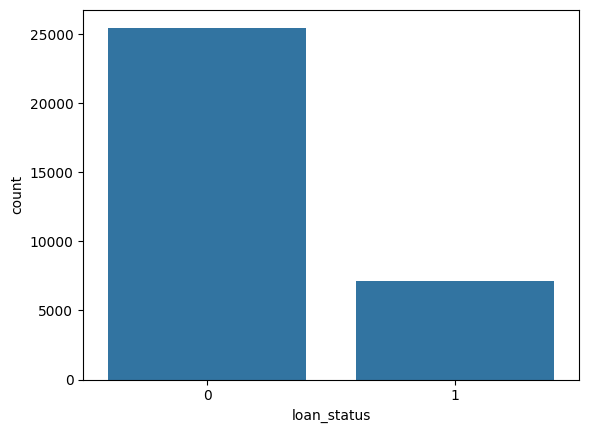

In [ ]:
sns.countplot(x="loan_status",data = df)

In [ ]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [ ]:
numerical_columns =df.select_dtypes(include=np.number).columns

In [ ]:
numerical_columns

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')

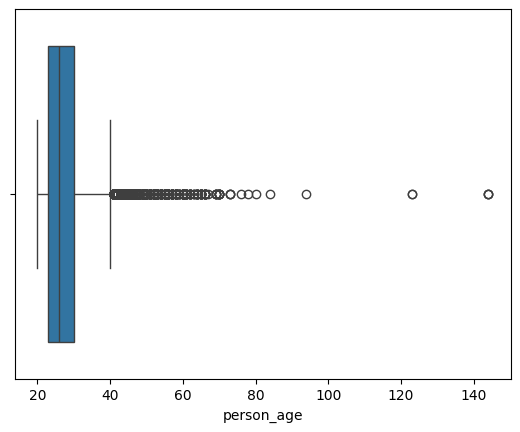

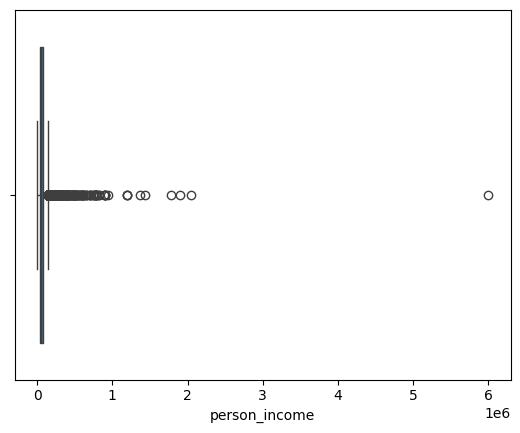

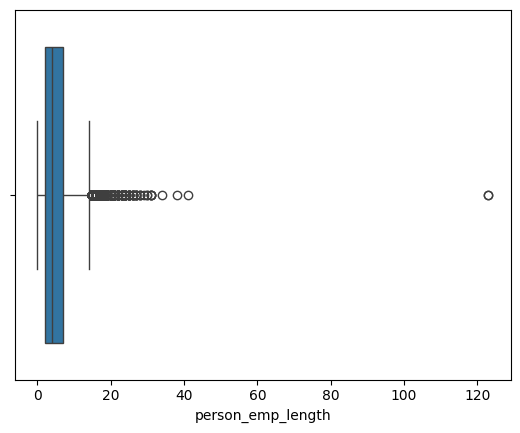

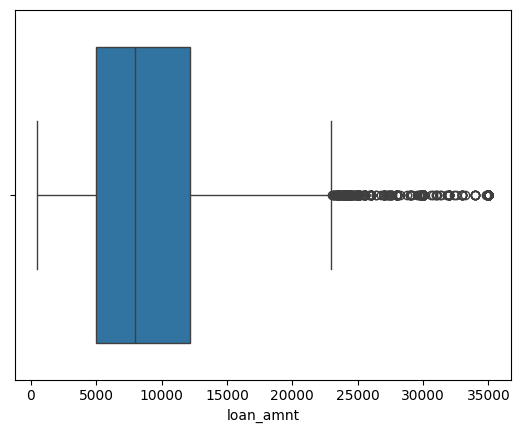

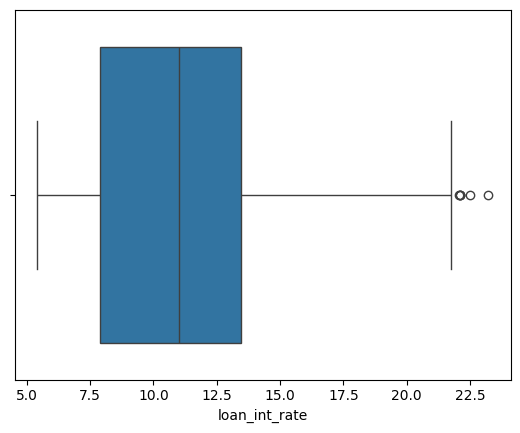

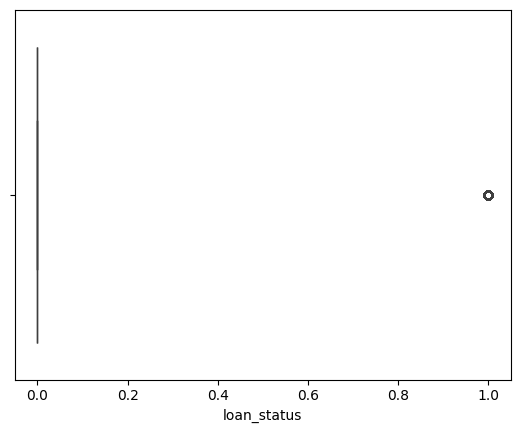

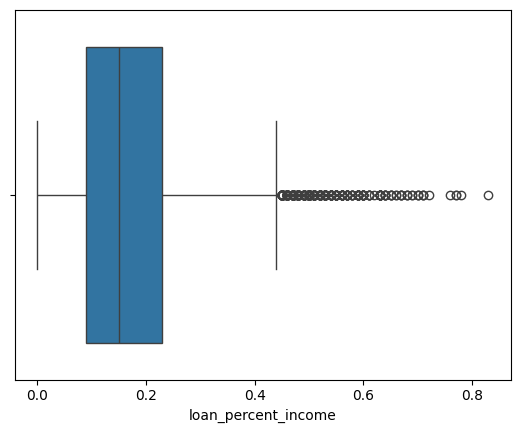

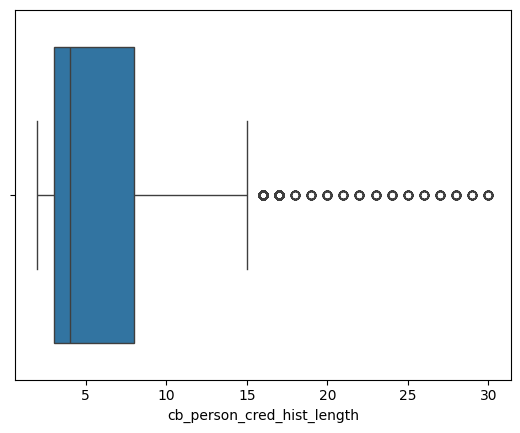

In [ ]:
for i in numerical_columns:
  sns.boxplot(x=df[i])
  plt.show()

In [ ]:
(df["person_age"] > 100).sum()

np.int64(5)

In [ ]:
(df["person_emp_length"]>60).sum()

np.int64(2)

<Axes: >

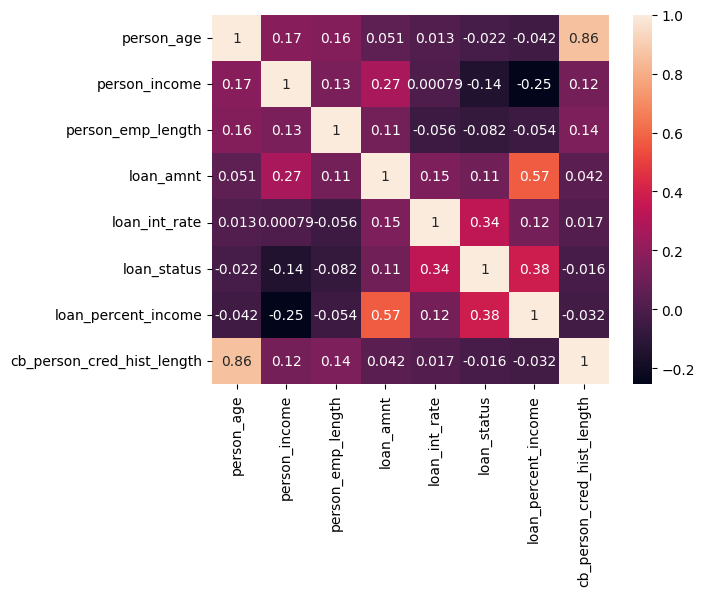

In [ ]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [ ]:
df_copy = df.copy()

In [ ]:
df_copy.drop_duplicates(inplace=True)

In [ ]:
df_copy.shape

(32416, 12)

In [ ]:
df_copy = df_copy[df["person_age"] >= 18]
df_copy = df_copy[df["person_age"]  <= 100]

In [ ]:
df_copy = df_copy[df_copy["person_emp_length"] <= df_copy["person_age"]]
df_copy = df_copy[df_copy["person_emp_length"] <= 60]

df_copy.shape

(31522, 12)

In [ ]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [ ]:
X = df_copy.drop("loan_status",axis=1)
y = df_copy["loan_status"]

In [ ]:
from sklearn.model_selection import train_test_split


In [ ]:
X_train,X_test , y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42 , stratify=y)

In [ ]:
numerical_col = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income',
       'cb_person_cred_hist_length']
categorical_col = ['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file']

In [ ]:
neg ,pos =  np.bincount(y_train)

In [ ]:
scale_weights = neg/pos

In [ ]:
scale_weights

np.float64(3.6312213039485766)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.impute import SimpleImputer

preprocessor_lr = ColumnTransformer(transformers=[
    ('num',Pipeline([
        ('imputer',SimpleImputer(strategy='median')),
        ('scaler',StandardScaler())
    ]),numerical_col),
    ('cat',Pipeline([
        ('imputer',SimpleImputer(strategy='constant' ,fill_value = "Missing")),
        ('encoder',OneHotEncoder(handle_unknown='ignore'))
    ]),categorical_col)
])


In [ ]:
preprocessor_xg = ColumnTransformer(transformers=[
    ('num',Pipeline([
        ('imputer',SimpleImputer(strategy='median'))
    ]),numerical_col),
    ('cat',Pipeline([
        ('imputer',SimpleImputer(strategy='constant' ,fill_value = "Missing")),
        ('encoder',OneHotEncoder(handle_unknown='ignore'))
    ]),categorical_col)
])


In [ ]:
from sklearn.model_selection import StratifiedKFold ,cross_validate
cv = StratifiedKFold(n_splits=5 , shuffle=True , random_state=42)
scoring = {
    'roc_auc': 'roc_auc',
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}


In [ ]:
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(max_iter=100,class_weight="balanced",random_state=42))
])

In [ ]:
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(
        max_depth=3,learning_rate=0.1,n_estimators=300,
        random_state=42,scale_pos_weight=scale_weights
        ))
])

In [ ]:
for cv_name , pipe in [('LogisticRegression',lr_cv_pipeline),('XGBClassifier',xgb_cv_pipeline)]:
  cv_results = cross_validate(pipe,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
  print()
  print(cv_name)
  print(f"ROC AUC: {cv_results['test_roc_auc'].mean():.3f}")
  print(f"Accuracy: {cv_results['test_accuracy'].mean():.3f}")
  print(f"Precision: {cv_results['test_precision'].mean():.3f}")
  print(f"Recall: {cv_results['test_recall'].mean():.3f}")


LogisticRegression
ROC AUC: 0.871
Accuracy: 0.812
Precision: 0.545
Recall: 0.778

XGBClassifier
ROC AUC: 0.940
Accuracy: 0.906
Precision: 0.775
Recall: 0.794


In [ ]:
cv_results

{'fit_time': array([1.30924249, 1.28626585, 0.84838772, 0.83244228, 0.47640944]),
 'score_time': array([0.11769271, 0.11874986, 0.12333417, 0.12559366, 0.07047915]),
 'test_roc_auc': array([0.94196603, 0.93126112, 0.94164805, 0.94298842, 0.94022443]),
 'test_accuracy': array([0.90463918, 0.91019033, 0.90561174, 0.90640492, 0.90065437]),
 'test_precision': array([0.77142857, 0.80576923, 0.77488789, 0.77085162, 0.75214408]),
 'test_recall': array([0.79338843, 0.76951331, 0.79338843, 0.80624426, 0.80532599]),
 'test_f1': array([0.78225441, 0.78722405, 0.78402904, 0.78815081, 0.77782705])}

In [ ]:
from sklearn.metrics._plot.precision_recall_curve import precision_recall_curve
from sklearn.metrics import confusion_matrix,accuracy_score,recall_score,f1_score,classification_report
def evaluate_model(model_name,model,X_test,y_test,threshold=None):
  print(f"Model Name = {model_name}")

  y_pred_prob = model.predict_proba(X_test)[:,1]
  if threshold:
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(X_test)

  print("Accuracy : ",accuracy_score(y_test,y_pred))
  print("Recall : ",recall_score(y_test,y_pred))
  print("F1 Score : ",f1_score(y_test,y_pred))
  print("Classification Report :")
  print(classification_report(y_test,y_pred))
  print("Confusion Matrix :")
  cm = confusion_matrix(y_test,y_pred)
  print(cm)
  sns.heatmap(cm , annot=True , fmt="d")
  plt.title("Confusion Matrix")
  plt.xlabel("Predicted Label")
  plt.ylabel("True Label")
  plt.show()

  precision , recalls , threshold = precision_recall_curve(y_test,y_pred_prob)
  plt.plot(recalls,precision)
  plt.title("Precision Recall Curve")
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.show()

In [ ]:
baseline_model = Pipeline([
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(class_weight="balanced"))
])
baseline_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

In [ ]:
xg_model = Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(max_depth=3,learning_rate=0.1,n_estimators=300,
        random_state=42,scale_pos_weight=scale_weights))
])
xg_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=3, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [ ]:
# Evaluation

Model Name = Baseline Model
Accuracy :  0.8193497224425059
Recall :  0.7870778267254038
F1 Score :  0.6530612244897959
Classification Report :
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305

Confusion Matrix :
[[4094  849]
 [ 290 1072]]


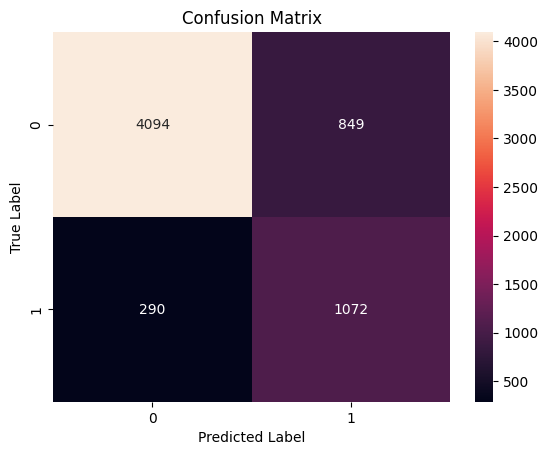

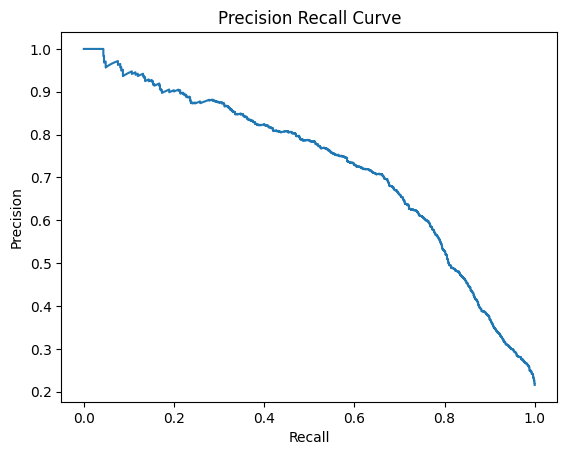

In [ ]:
evaluate_model("Baseline Model",baseline_model,X_test,y_test)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint , uniform

In [ ]:
param_grid = {
    "classifier__n_estimators":randint(150,600),
    "classifier__max_depth":randint(3,10),
    "classifier__learning_rate":uniform(0.01,0.5),
    "classifier__subsample":uniform(0.5,1.0),
    "classifier__colsample_bytree":uniform(0.5,1.0),
    "classifier__min_child_weight":randint(1,10),
    "classifier__gamma":uniform(0.0,5.0),
}

In [ ]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)
random_search.fit(X_train,y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7d13653bd6d0>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7d136578ba10>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7d13653bd310>},
                   scoring='average_precision', verbose=1)

In [ ]:
best_parameters = random_search.best_params_

Model Name = XG-Boots
Accuracy :  0.957845897608756
Recall :  0.8984389348025712
F1 Score :  0.9020005531483359
Classification Report :
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     19772
           1       0.91      0.90      0.90      5445

    accuracy                           0.96     25217
   macro avg       0.94      0.94      0.94     25217
weighted avg       0.96      0.96      0.96     25217

Confusion Matrix :
[[19262   510]
 [  553  4892]]


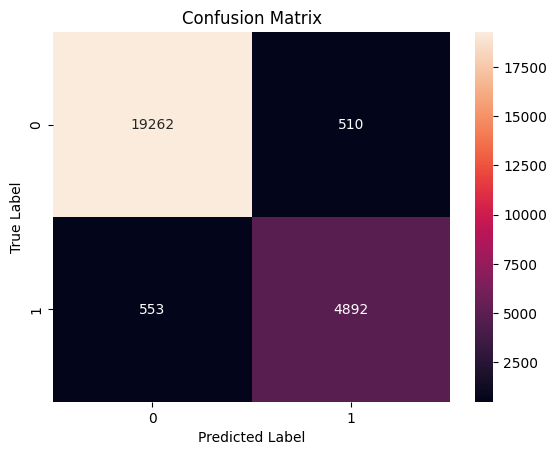

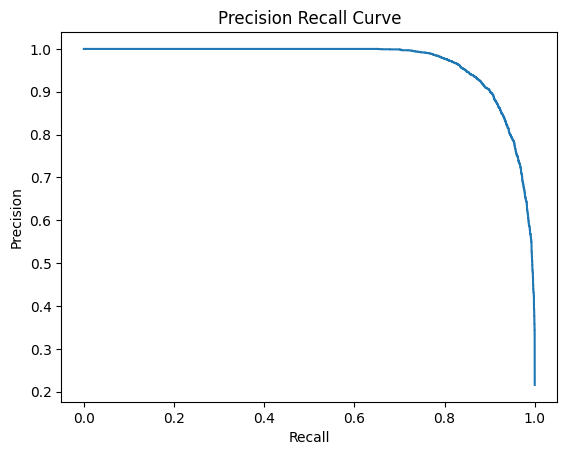

In [ ]:
evaluate_model("XG-Boots",random_search,X_train,y_train)

Model Name = XGBoost
Accuracy :  0.7839809674861221
Recall :  0.0
F1 Score :  0.0
Classification Report :
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4943
           1       0.00      0.00      0.00      1362

    accuracy                           0.78      6305
   macro avg       0.39      0.50      0.44      6305
weighted avg       0.61      0.78      0.69      6305

Confusion Matrix :
[[4943    0]
 [1362    0]]


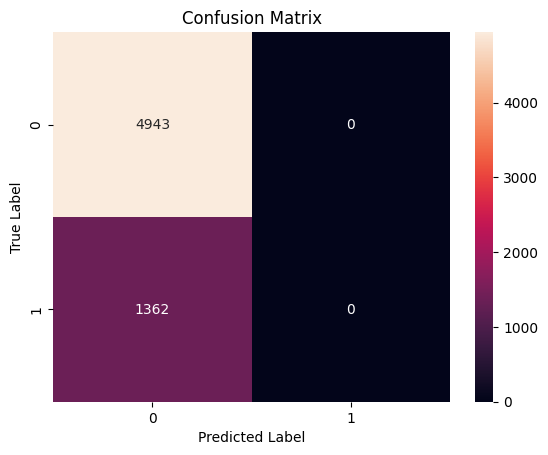

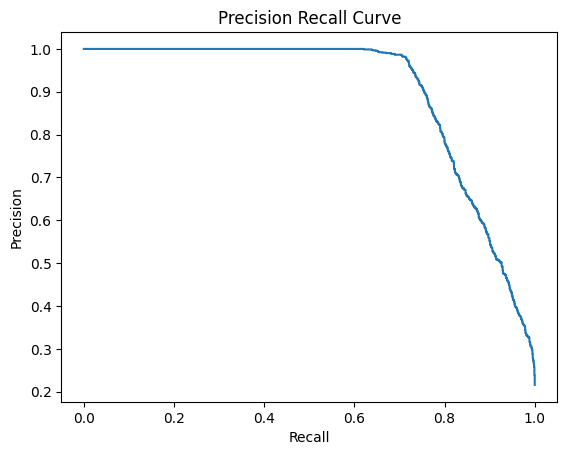

In [ ]:
prob = xg_model.predict_proba(X_train)[:,1]
precisions , recalls , thresholds = precision_recall_curve(y_train,prob)
f1 = 2*(precisions - recalls)/(precisions+recalls+1e-9)
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]
evaluate_model("XGBoost",xg_model,X_test,y_test,best_threshold)

In [ ]:
from sklearn.calibration import CalibratedClassifierCV,calibration_curve
calibrated_model_isotonic = CalibratedClassifierCV(xg_model,cv=5,method="isotonic")
calibrated_model_isotonic.fit(X_train,y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=0.1,
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=3,
                                                                max_leaves=None,
                                                                min_child_weight=None,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=300,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]),
                       method='isotonic')

In [ ]:
calibrated_model_sigmoid = CalibratedClassifierCV(xg_model,cv=5,method="sigmoid")
calibrated_model_sigmoid.fit(X_train,y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                feature_weights=None,
                                                                gamma=None,
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=0.1,
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=3,
                                                                max_leaves=None,
                                                                min_child_weight=None,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=300,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [ ]:
uncalibrated = xg_model.predict_proba(X_train)[:,1]
uncalibrated


array([0.33731586, 0.263583  , 0.0457034 , ..., 0.13970327, 0.63427365,
       0.6035123 ], dtype=float32)

In [ ]:
calibrated_sig = calibrated_model_sigmoid.predict_proba(X_train)[:,1]
calibrated_sig

array([0.10563471, 0.07213948, 0.01300845, ..., 0.02200828, 0.59362238,
       0.46490264])

In [ ]:
calibrated_iso = calibrated_model_isotonic.predict_proba(X_train)[:,1]
calibrated_iso

array([0.11863272, 0.10069733, 0.00576692, ..., 0.03085148, 0.35777628,
       0.27648575])

In [ ]:
actual_uncal , predicted_uncal = calibration_curve(y_train,uncalibrated)
actual_cal_sig , predicted_cal_sig = calibration_curve(y_train,calibrated_sig)
actual_cal_iso , predicted_cal_iso = calibration_curve(y_train,calibrated_iso)

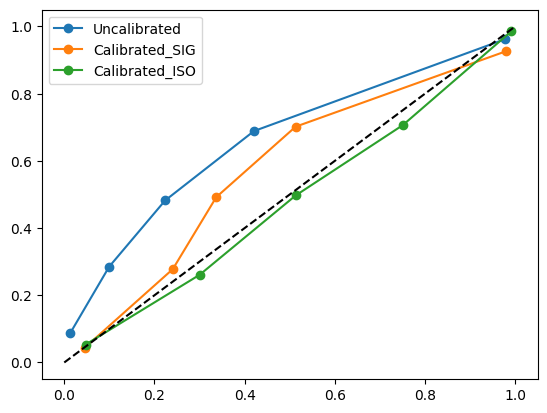

In [69]:
plt.plot(actual_uncal,predicted_uncal,"o-",label="Uncalibrated")
plt.plot(actual_cal_sig,predicted_cal_sig,"o-",label="Calibrated_SIG")
plt.plot(actual_cal_iso,predicted_cal_iso,"o-",label="Calibrated_ISO")
plt.plot([0,1],[0,1],linestyle="--",color="black")
plt.legend()

In [ ]:
!pip install shap

In [71]:
xgb_classifier = xg_model.named_steps["classifier"]
xgb_classifier

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=300,
              n_jobs=None, num_parallel_tree=None, ...)

In [75]:
X_test_transformed = xg_model.named_steps["preprocessor"].transform(X_test)

In [78]:
feature_names = xg_model.named_steps["preprocessor"].get_feature_names_out()

In [79]:
X_test_df = pd.DataFrame(X_test_transformed,columns=feature_names)

In [81]:
import shap
explainer = shap.TreeExplainer(xgb_classifier)

In [82]:
shap_values = explainer.shap_values(X_test_df)

In [83]:
shap_values

array([[-3.09936088e-02,  2.61651605e-01,  3.24727535e-01, ...,
        -1.11471852e-02, -1.09386537e-03,  0.00000000e+00],
       [ 8.81711300e-03, -7.75206685e-01, -2.68906429e-02, ...,
        -1.16033806e-02,  1.24394079e-04,  0.00000000e+00],
       [ 6.49962649e-02,  3.95627952e+00,  7.61548728e-02, ...,
        -1.04063004e-02, -7.36535410e-04,  0.00000000e+00],
       ...,
       [-1.07465656e-02,  6.23344302e-01,  6.20719157e-02, ...,
        -1.11954585e-02, -1.09386537e-03,  0.00000000e+00],
       [ 2.20926162e-02, -7.16835022e-01,  7.13339597e-02, ...,
        -1.17389513e-02, -4.15484235e-03,  0.00000000e+00],
       [-1.53162535e-02, -7.68949807e-01,  2.85876766e-02, ...,
        -1.13214497e-02, -1.63165736e-03,  0.00000000e+00]], dtype=float32)

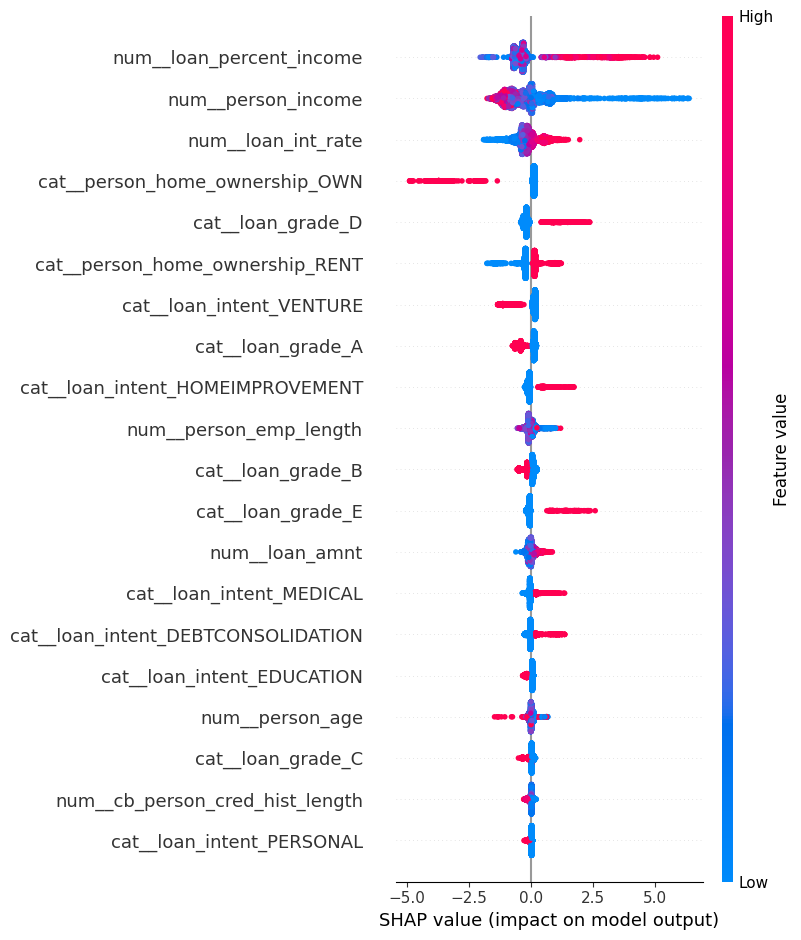

In [84]:
shap.summary_plot(shap_values,X_test_df)

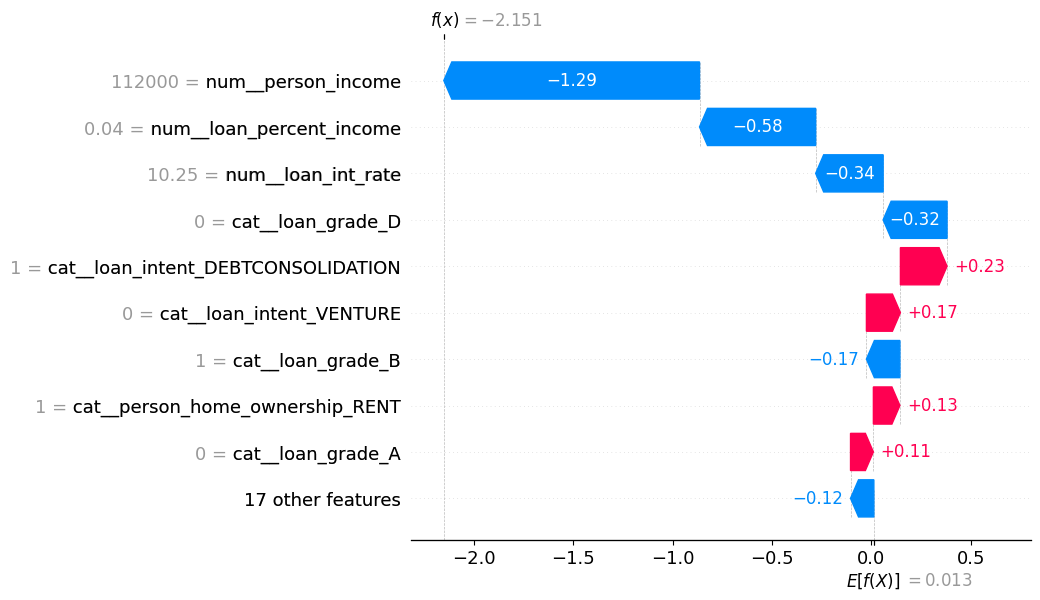

In [85]:
row_index = 10

shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[row_index],
        base_values=explainer.expected_value,
        data=X_test_df.iloc[row_index],
        feature_names=X_test_df.columns
    )
)

In [86]:
y_pred = random_search.predict(X_test)

In [90]:
result_df = X_test.copy()
result_df["actual"] = y_test
result_df["predicted"] = y_pred

In [91]:
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,0
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11661,21,75000,MORTGAGE,5.0,PERSONAL,C,20000,13.11,0.27,Y,2,0,0
27837,29,265000,MORTGAGE,2.0,PERSONAL,B,25000,11.26,0.09,N,10,0,0
17192,25,48996,MORTGAGE,8.0,MEDICAL,B,5000,9.88,0.10,N,2,1,1
26858,27,115000,MORTGAGE,11.0,MEDICAL,A,8000,7.51,0.07,N,7,0,0


In [92]:
false_pos = result_df[(result_df["actual"] == 0) & (result_df["predicted"] == 1)]
false_neg = result_df[(result_df["actual"] == 1) & (result_df["predicted"] == 0)]

In [94]:
len(false_pos)


223

In [95]:
len(false_neg)

271

In [96]:
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(best_model,cv=5,method="isotonic")
calibrated_model.fit(X_train,y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.07597067003566026),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=7,
                                                                max_leaves=None,
                                                                min_child_weight=7,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=385,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]),
                       method='isotonic')

In [97]:
import joblib
joblib.dump(calibrated_model,"credit_risk_model.pkl")

['credit_risk_model.pkl']

In [99]:
joblib.dump(best_threshold,"best_threshold.pkl")

['best_threshold.pkl']